In [109]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)


Using: cuda


In [110]:
import pandas as pd

In [111]:
df_train = pd.read_csv('../../data/sentiment-analysis-on-movie-reviews/train.tsv', sep='\t')
df_test = pd.read_csv('../../data/sentiment-analysis-on-movie-reviews/test.tsv', sep='\t')

In [112]:
df_train.head()

,PhraseId,SentenceId,Phrase,Sentiment
0,1,1,A series of escapades demonstrating the adage ...,1
1,2,1,A series of escapades demonstrating the adage ...,2
2,3,1,A series,2
3,4,1,A,2
4,5,1,series,2


In [113]:
df_train = df_train.drop('PhraseId', axis=1)

In [114]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 156060 entries, 0 to 156059
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   SentenceId  156060 non-null  int64
 1   Phrase      156060 non-null  str  
 2   Sentiment   156060 non-null  int64
dtypes: int64(2), str(1)
memory usage: 3.6 MB


In [115]:
df_train['SentenceId'].unique()

array([   1,    2,    3, ..., 8542, 8543, 8544], shape=(8529,))

Data Visualisation

In [116]:
import matplotlib.pyplot as plt
import seaborn as sns

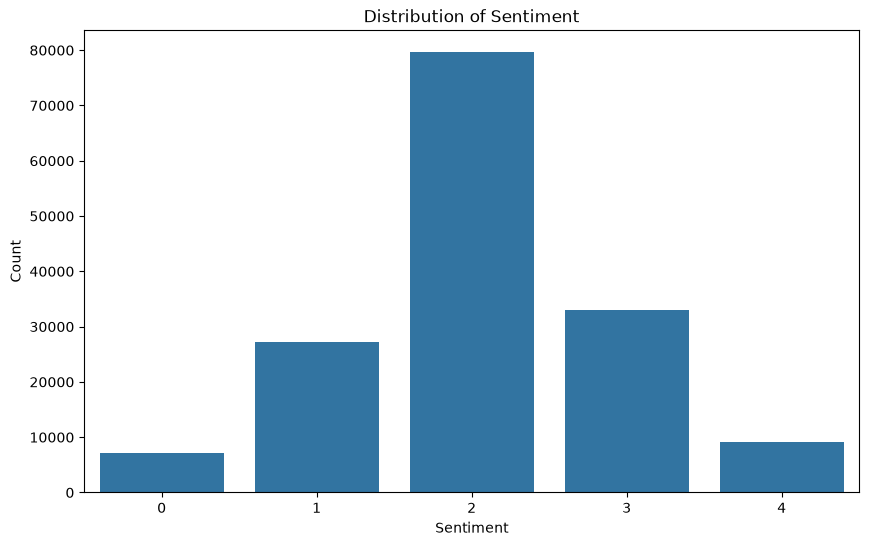

In [117]:
plt.figure(figsize=(10,6))
sns.countplot(x=df_train['Sentiment'])
plt.title('Distribution of Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

In [118]:
from wordcloud import WordCloud

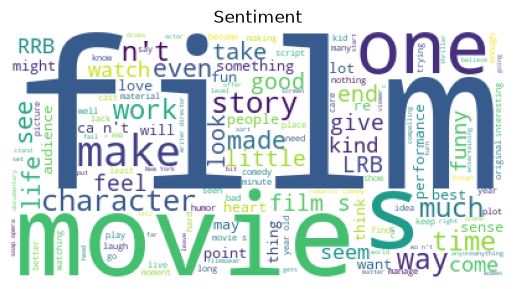

In [119]:
#WoldClaud

wc = WordCloud(width=400, height=200, background_color='white', max_words=2000, max_font_size=400).generate(" ".join(df_train['Phrase']))

plt.imshow(wc)
plt.axis('off')
plt.title('Sentiment')
plt.show()
plt.close()

In [120]:
import torch, torchvision, torchaudio

print("Torch:", torch.__version__, "CUDA:", torch.version.cuda)
print("Torchvision:", torchvision.__version__)
print("Torchaudio:", torchaudio.__version__)
print("GPU aktif:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))


Torch: 2.14.1+cu132 CUDA: 13.2
Torchvision: 0.29.1+cu132
Torchaudio: 2.11.0+cpu
GPU aktif: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [121]:
print(df_train.isnull().sum())

SentenceId    0
Phrase        0
Sentiment     0
dtype: int64


In [122]:
df_train.duplicated().sum()

np.int64(0)

In [123]:
from collections import Counter

In [124]:
all_words = " ".join(df_train['Phrase'].dropna()).lower().split()
word_freq = Counter(all_words)
print(word_freq.most_common(20))


[('the', 51220), (',', 42006), ('a', 36123), ('of', 32308), ('and', 31763), ('to', 22448), ('.', 17565), ("'s", 16971), ('in', 13745), ('is', 13447), ('that', 12327), ('it', 11677), ('as', 8623), ('with', 7750), ('for', 7417), ('its', 7051), ('film', 6689), ('an', 6479), ('movie', 5905), ('this', 5677)]


In [125]:
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.corpus import stopwords

In [126]:
import re
import string

In [127]:
stop_word = stopwords.words('english') #kata umum dari bahasa inggris yang tidak pynya arti penting

def clean_text(text):
    text = text.lower() #ubah semua menjadi lowercase
    text = re.sub(r"\d+", " ", text) #hapus angka
    text = re.sub(f"[{string.punctuation}]", " ", text) #hapus tanda baca
    text = re.sub(r"[^a-zA-Z0-9]", " ", text) #hapus non-alphabeth
    text = re.sub(r"\s+", " ", text) #rapikan spasi
    words = [w for w in text.split() if len(w) > 2 and len(w) < 20] #filter kata pendek
    return " ".join(words) #gabungkan lagi jdi string dengan pemisah " "

df_train['clean_phrase'] = df_train["Phrase"].apply(clean_text)


vectorizer = TfidfVectorizer(
    stop_words=stop_word, #hapus kata umum
    max_df=0.8, #buang kata yang muncul lebih dari 80%
    min_df=2, #buang kata jarang
)

X_tfidv = vectorizer.fit_transform(df_train['clean_phrase'])

print("Jumlah fitur setelah preprocessing:", len(vectorizer.get_feature_names_out()))
print("Contoh fitur:", vectorizer.get_feature_names_out()[:100])

Jumlah fitur setelah preprocessing: 14871
Contoh fitur: ['aaa' 'aaliyah' 'aan' 'abagnale' 'abandon' 'abandoned' 'abbass' 'abbott'
 'abbreviated' 'abc' 'abderrahmane' 'abdul' 'abel' 'abhorrent' 'abhors'
 'abiding' 'abilities' 'ability' 'abject' 'able' 'ably' 'abomination'
 'aboriginal' 'aborted' 'abound' 'abrahams' 'abrasive' 'abridged' 'abroad'
 'abrupt' 'absence' 'absent' 'absolute' 'absolutely' 'absorb' 'absorbed'
 'absorbing' 'absorbs' 'absorption' 'abstract' 'absurd' 'absurdist'
 'absurdities' 'absurdity' 'absurdly' 'abundant' 'abundantly' 'abuse'
 'abused' 'abysmal' 'abysmally' 'abyss' 'academic' 'academy' 'accent'
 'accents' 'accentuating' 'accept' 'acceptable' 'acceptance' 'accepting'
 'accepts' 'access' 'accessibility' 'accessible' 'accident' 'accidental'
 'acclaim' 'acclaimed' 'accommodate' 'accomodates' 'accompanied'
 'accompanies' 'accompanying' 'accomplish' 'accomplished' 'accomplishes'
 'accomplishment' 'accomplishments' 'according' 'account' 'accountant'
 'accumulate' 'ac

Data Split, persiapan Modeling

In [128]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidv, df_train['Sentiment'], test_size=0.2, random_state=42
)

Mengatasi masalah class imbalance hanya pada data train

In [129]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)


In [139]:
# from sklearn.linear_model import LogisticRegression
#
# model = LogisticRegression(
#     max_iter=1000,
#     class_weight='balanced'
# )
# model.fit(X_train, y_train)

# from sklearn.ensemble import RandomForestClassifier
# model = RandomForestClassifier(
#     n_estimators=100,
#     class_weight='balanced',
#     random_state=42
# )


import xgboost as xgb
model = xgb.XGBClassifier(
    n_estimators=100,
   device='cuda',
    class_weight='balanced'
)
model.fit(X_train_res, y_train_res)


C:\Users\hajar\Documents\gemastik-xix\JupyterProject\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [07:06:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "class_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from skle

In [140]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.38      0.47      0.42      1416
           1       0.46      0.29      0.36      5527
           2       0.66      0.82      0.73     15639
           3       0.51      0.28      0.36      6707
           4       0.37      0.53      0.44      1923

    accuracy                           0.58     31212
   macro avg       0.48      0.48      0.46     31212
weighted avg       0.56      0.58      0.55     31212



📊 Arti Setiap Bagian
1. Per Kelas (0–4)
Precision → seberapa banyak prediksi kelas itu yang benar.
Misalnya kelas 0 punya precision 0.61 → dari semua prediksi “kelas 0”, hanya 61% yang benar.

2. Recall → seberapa banyak data kelas itu berhasil ditangkap.
Misalnya kelas 0 recall 0.19 → dari semua data yang benar-benar kelas 0, hanya 19% yang berhasil dikenali.

3. F1-score → kombinasi precision dan recall (harmonis).
Misalnya kelas 2 punya F1-score 0.76 → cukup baik karena recall tinggi (0.88).

4. Support → jumlah data asli di kelas itu.
Misalnya kelas 2 punya support 15.639 → paling banyak dibanding kelas lain.